/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP evaluated on 256 held-out rows.
=== Top 20 Features by SHAP Importance (Random Forest, class 1) ===
                                                   Feature  Mean_SHAP_Value
                       android.permission.READ_PHONE_STATE         0.193708
                com.google.android.c2dm.permission.RECEIVE         0.084492
                 android.permission.RECEIVE_BOOT_COMPLETED         0.059373
                 android.permission.ACCESS_COARSE_LOCATION         0.044088
          com.android.launcher.permission.INSTALL_SHORTCUT         0.043432
                              android.permission.GET_TASKS         0.033994
                  android.permission.READ_EXTERNAL_STORAGE         0.025404
                    android.permission.SYSTEM_ALERT_WINDOW         0.025078
                   android.permission.ACCESS_FINE_LOCATION         0.023367
                               com.android.vending.BILLING         0.023043
                              android.permission.WAKE_LOCK 

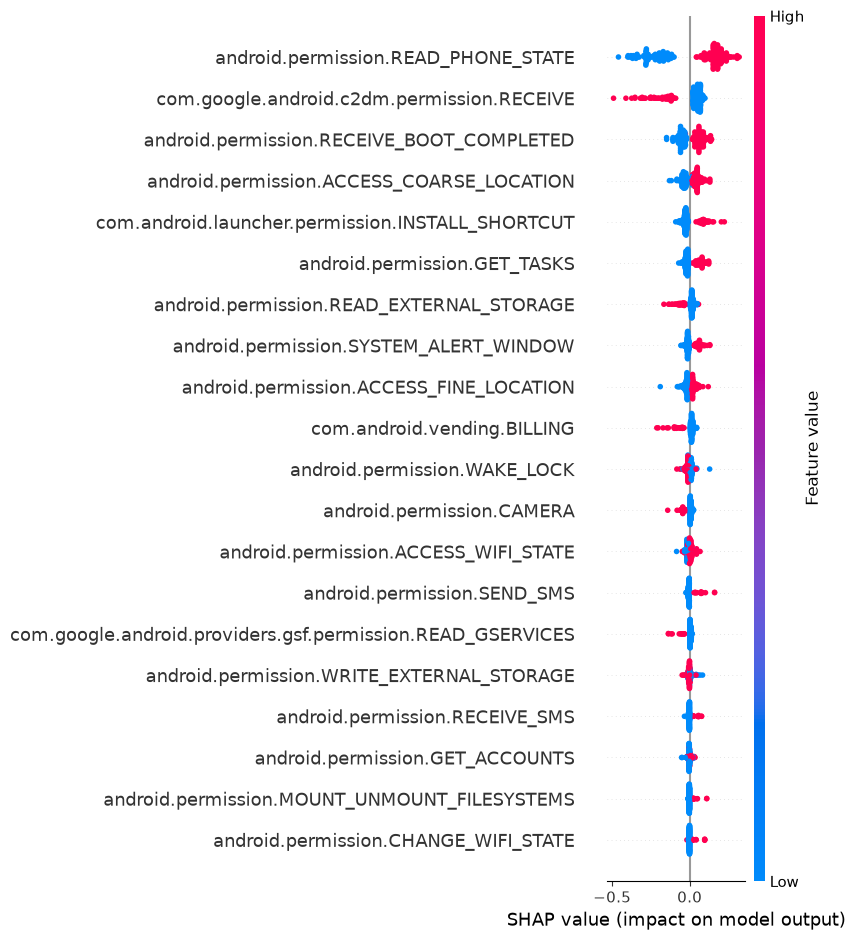

In [ ]:
import pandas as pd
import numpy as np
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Load Dataset
df = pd.read_csv("data.csv")

# Separate Features (X) and Target (y)
target_col = "Result"
X = df.drop(columns=[target_col])
y = df[target_col]

# Train-Test Split (80/20 Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Train Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

# Compute SHAP Values
X_shap = X_test.sample(n=min(256, len(X_test)), random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_shap)

# Select class 1 (the positive / malware class) when SHAP returns per-class values.
if shap_values.values.ndim == 3:
    class_index = list(model.classes_).index(1)
    shap_vals_matrix = shap_values.values[:, :, class_index]
else:
    shap_vals_matrix = shap_values.values

# Rank features by mean absolute SHAP value
mean_abs_shap = np.abs(shap_vals_matrix).mean(axis=0)
shap_ranking = pd.DataFrame({
    "Feature": X.columns,
    "Mean_SHAP_Value": mean_abs_shap
}).sort_values(by="Mean_SHAP_Value", ascending=False).reset_index(drop=True)

# Display the top 20 features
top_20_features = shap_ranking.head(20)
print(f"SHAP evaluated on {len(X_shap)} held-out rows.")
print("=== Top 20 Features by SHAP Importance (Random Forest, class 1) ===")
print(top_20_features.to_string(index=False))

# Plot SHAP importance for the test set
shap.summary_plot(shap_vals_matrix, X_shap, max_display=20)